In [2]:
import os

path = "/mnt/c/Users/Walker/Documents/website_1/notebooks/age_model_1_no_croping.keras"

print("exists:", os.path.exists(path))
if os.path.exists(path):
    print("size (MB):", os.path.getsize(path) / 1e6)
    print("modified:", os.path.getmtime(path))


exists: False


In [1]:
import pandas as pd 
import tensorflow as tf
import matplotlib.pyplot as plt
import os, sys
import numpy as np
from datetime import datetime



In [2]:
os.listdir(os.path.join(data_dir, age_dirs[0]))

NameError: name 'data_dir' is not defined

In [2]:
### Data from https://data.vision.ee.ethz.ch/cvl/rrothe/imdb-wiki/

#Create data fram for each file 
data_dir = '../data/imdb_crop/imdb_crop'
dirs = [dir for dir in os.listdir(data_dir) if not dir.startswith('.')]
files_dict = dict()
for dir in dirs:
    files_dict[dir] = os.listdir(data_dir + "/" + dir)


files_dict
file_paths = list()
for key, value in files_dict.items():
    for file in value:
        file_paths.append(data_dir + '/' + key +'/' + file)

file_paths

['../data/imdb_crop/imdb_crop/00/nm0000100_rm1001569280_1955-1-6_2011.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1002674432_1955-1-6_2003.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1018346496_1955-1-6_2011.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1019451648_1955-1-6_2003.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm103389184_1955-1-6_2005.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1035123712_1955-1-6_2011.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1036228864_1955-1-6_2003.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1051900928_1955-1-6_2011.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1069783296_1955-1-6_2003.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1079482368_1955-1-6_2007.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1096259584_1955-1-6_2007.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm1129814016_1955-1-6_2007.jpg',
 '../data/imdb_crop/imdb_crop/00/nm0000100_rm113481984_1955-1-6_2003.jpg',
 '../data/imdb

In [3]:
#Extract ages from the file names

def file_path_to_age(path: str) -> float:
    """Converts file path to age in years"""
    strings = path.split('/')
    string = strings[-1]
    strs = string.split('_')
    dates = [strs[-2], strs[-1].strip('.jpg')]
    born = [int(value) if int(value) != 0 else 1 for value in dates[0].strip(' ').split('-')]
    photo_taken = int(dates[1])
    days =  datetime(photo_taken, 1, 1)- datetime(*born)
    years = days.days/365.25
    return years

#Create data frame
df = pd.DataFrame()
df['paths'] = file_paths
df['age'] = df.paths.apply(file_path_to_age)
df.head()

,paths,age
0,../data/imdb_crop/imdb_crop/00/nm0000100_rm100...,55.986311
1,../data/imdb_crop/imdb_crop/00/nm0000100_rm100...,47.986311
2,../data/imdb_crop/imdb_crop/00/nm0000100_rm101...,55.986311
3,../data/imdb_crop/imdb_crop/00/nm0000100_rm101...,47.986311
4,../data/imdb_crop/imdb_crop/00/nm0000100_rm103...,49.987680


In [4]:
df['age_year']= df.age.apply(lambda x: int(round(x)))
df

,paths,age,age_year
0,../data/imdb_crop/imdb_crop/00/nm0000100_rm100...,55.986311,56
1,../data/imdb_crop/imdb_crop/00/nm0000100_rm100...,47.986311,48
2,../data/imdb_crop/imdb_crop/00/nm0000100_rm101...,55.986311,56
3,../data/imdb_crop/imdb_crop/00/nm0000100_rm101...,47.986311,48
4,../data/imdb_crop/imdb_crop/00/nm0000100_rm103...,49.987680,50
...,...,...,...
460718,../data/imdb_crop/imdb_crop/99/nm3724099_rm129...,12.492813,12
460719,../data/imdb_crop/imdb_crop/99/nm3724099_rm276...,12.492813,12
460720,../data/imdb_crop/imdb_crop/99/nm3724099_rm281...,12.492813,12
460721,../data/imdb_crop/imdb_crop/99/nm3724099_rm291...,12.492813,12


In [6]:
df.to_csv('data.csv')

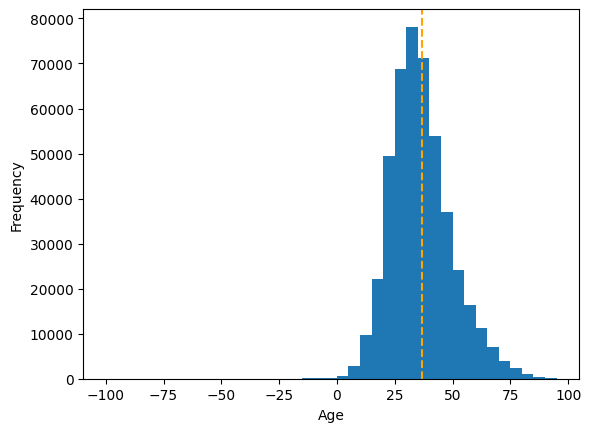

In [11]:
#Age distribution
plt.hist(df.age, range=(0,100), bins=range(-100,100, 5))
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.axvline(x=df.age.mean(), color = 'orange', linestyle='--', label='Average Age')
plt.legend
plt.show()

In [3]:
import pandas as pd
df = pd.read_csv('~/Documents/MATLAB/imdb.csv')

In [6]:
df.celeb_id.nunique()

20284

In [9]:
df.columns

Index(['dob_serial', 'photo_taken', 'age', 'full_path', 'gender', 'name', 'x1',
       'y1', 'x2', 'y2', 'face_score', 'second_face_score', 'celeb_id'],
      dtype='object')

In [15]:
df.gender.value_counts()

gender
1.0    263214
0.0    189047
Name: count, dtype: int64

(array([62302.,     0., 37001., 65215., 89819., 93477., 73375., 33842.,
         5502.,   190.]),
 array([-1.        , -0.16183112,  0.67633775,  1.51450663,  2.3526755 ,
         3.19084438,  4.02901326,  4.86718213,  5.70535101,  6.54351988,
         7.38168876]),
 <BarContainer object of 10 artists>)

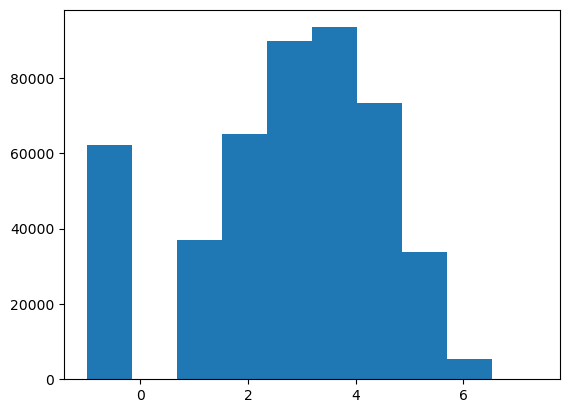

In [21]:
import matplotlib.pyplot as plt
import numpy as np
plt.hist(x=df.face_score.replace(-np.inf, -1))

In [4]:
df.shape

(460723, 13)

In [34]:
df['path'] = '../data/imdb_crop/imdb_crop/' + df.full_path

In [35]:
df['path'] = df['age'].astype('str') + '/' + df.path

In [36]:
import shutil
from pathlib import Path

src_root = Path("../data/imdb_crop/imdb_crop")
dst_root = Path("../data/age_dir")   # <- this will be your image_dataset_from_directory root
dst_root.mkdir(parents=True, exist_ok=True)

for full_path, age in zip(df["full_path"], df["age"]):
    src = src_root / full_path                  # e.g. ../data/imdb_crop/imdb_crop/01/xxx.jpg
    label_dir = dst_root / str(int(age))        # e.g. ../data/age_dir/69
    label_dir.mkdir(parents=True, exist_ok=True)

    dst = label_dir / src.name                  # flatten within age label
    shutil.copy2(src, dst)                      # use move() if you want to remove originals


In [37]:
from pathlib import Path

root = Path("../data/age_dir")
exts = {".jpg", ".jpeg", ".png", ".webp"}

total = sum(1 for p in root.rglob("*") if p.is_file() and p.suffix.lower() in exts)
print("total images:", total)


total images: 460723


In [14]:
img_full = tf.image.decode_jpeg(tf.io.read_file(path), channels=3)
H, W = img_full.shape[:2]
x1, y1, x2, y2 = df.loc[0, ['x1','y1','x2','y2']]
print("image W,H:", W, H)
print("box x1,y1,x2,y2:", x1, y1, x2, y2)


image W,H: 257 257
box x1,y1,x2,y2: 1072.926 161.838 1214.784 303.696


In [ ]:
split_id = int(.8*df.shape[0])
train_X, val_X = df.paths[:split_id], df.paths[split_id:]
train_X

0         ../data/imdb_crop/61/nm0861361_rm575703808_196...
1         ../data/imdb_crop/61/nm0694361_rm3713568512_19...
2         ../data/imdb_crop/61/nm0115161_rm1289919232_19...
3         ../data/imdb_crop/61/nm0166061_rm3965158912_19...
4         ../data/imdb_crop/61/nm0143261_rm4154955776_19...
                                ...                        
368573    ../data/imdb_crop/83/nm0001083_rm4032724992_19...
368574    ../data/imdb_crop/83/nm0005683_rm580813824_194...
368575    ../data/imdb_crop/83/nm0756983_rm3089807616_19...
368576    ../data/imdb_crop/83/nm1087183_rm825667072_197...
368577    ../data/imdb_crop/83/nm0680983_rm459704576_198...
Name: paths, Length: 368578, dtype: object

In [12]:
batch_size = 32
img_height = 224
img_width = 224

split_id = int(.8*df.shape[0])
train_X, val_X = df.paths[:split_id], df.paths[split_id:]
train_y, val_y = df.age[:split_id], df.age[split_id:]

#dataset = tf.data.Dataset.from_tensor_slices((X.values, y.values))

def image_feeder(path:str, age: float) -> any:
    image_bytes = tf.io.read_file(path)
    img = tf.image.decode_jpeg(image_bytes)
    img = tf.image.resize(img, [img_height, img_width])
    img = tf.cast(img, tf.float32)
    return img, age

AUTOTUNE = tf.data.experimental.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices((train_X, train_y))

train_ds = (
    train_ds.map(image_feeder).cache().prefetch(buffer_size=AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((val_X, val_y))

val_ds = (
    val_ds.map(image_feeder).cache().prefetch(buffer_size=AUTOTUNE)
)




I0000 00:00:1768774019.212572   43692 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9558 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:0a:00.0, compute capability: 8.9


In [ ]:
IMG_SHAPE = (224,224) + (3,)
base_model = tf.keras.applications.ResNet50(
    include_top=True,
    weights='imagenet',
    input_shape=IMG_SHAPE,
)

In [5]:

data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])


for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

I0000 00:00:1768774240.969320   49381 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9558 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:0a:00.0, compute capability: 8.9


NameError: name 'train_ds' is not defined

In [ ]:
import pathlib 
data_dir = '../data/imdb_crop'
data_dir = pathlib.Path(data_dir).with_suffix('')

batch_size = 32
img_height = 224
img_width = 224

train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=11,
  image_size=(img_height, img_width),
  batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=11,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 460723 files belonging to 100 classes.
Using 368579 files for training.
Found 460723 files belonging to 100 classes.
Using 92144 files for validation.


AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

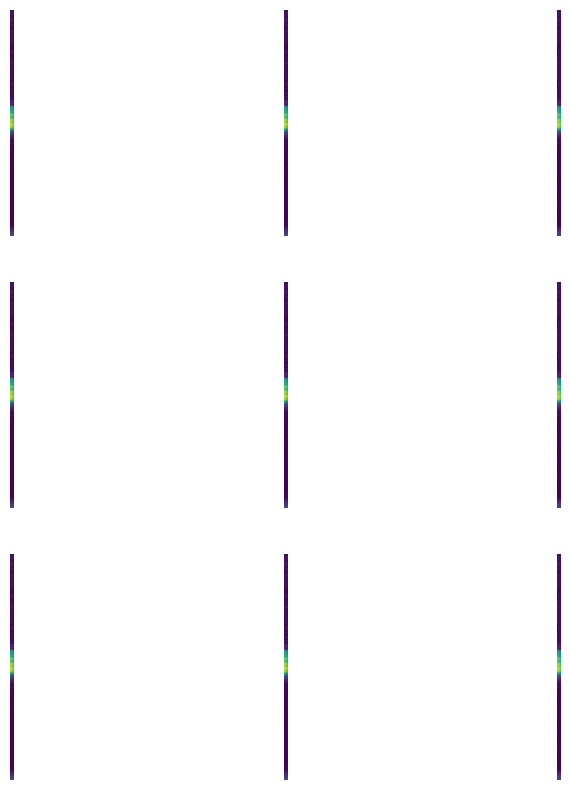

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    #plt.title(class_names[labels[i]])
    plt.axis("off")

In [ ]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [ ]:
rescale = tf.keras.layers.Rescaling(1./127.5, offset=-1)
IMG_SHAPE = (224,224) + (3,)
# Create the base model from the pre-trained model MobileNet V2
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
batch_size = 32
img_height = 224
img_width = 224
AUTOTUNE = tf.data.AUTOTUNE

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def image_feeder(path: str, age: float):
    image_bytes = tf.io.read_file(path)
    img = tf.image.decode_jpeg(image_bytes, channels=3)          # ensure 3 channels
    img = tf.image.resize(img, [img_height, img_width])
    img = tf.cast(img, tf.float32)                               # mobilenet expects float32
    img = preprocess_input(img)                                  # scales to [-1, 1]
    age = tf.cast(age, tf.float32)
    return img, age

train_ds = tf.data.Dataset.from_tensor_slices((train_X, train_y))
train_ds = (
    train_ds
    .shuffle(buffer_size=len(train_X), reshuffle_each_iteration=True)
    .map(image_feeder, num_parallel_calls=AUTOTUNE)
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((val_X, val_y))
val_ds = (
    val_ds
    .map(image_feeder, num_parallel_calls=AUTOTUNE)
    .batch(batch_size)
    .prefetch(AUTOTUNE)
)

IMG_SHAPE = (224, 224, 3)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet",
)

image_batch, label_batch = next(iter(train_ds))
feature_batch = base_model(image_batch)
print(image_batch.shape)   # (32, 224, 224, 3)
print(feature_batch.shape)


2026-01-18 17:07:26.286803: W tensorflow/core/kernels/data/cache_dataset_ops.cc:917] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2026-01-18 17:07:26.461951: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91800


(32, 224, 224, 3)
(32, 7, 7, 1280)


In [ ]:
base_model.trainable = False

In [ ]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


In [ ]:
base_model.trainable = False
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)
prediction_layer = tf.keras.layers.Dense(1, activation='relu')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)
inputs = tf.keras.Input(shape=(160, 160, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

(32, 1280)
(32, 1)


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'input_layer' of layer 'functional' is incompatible with the layer: expected shape=(None, 224, 3), found shape=(None, 160, 160, 3)[0m

Arguments received by Sequential.call():
  • args=('<KerasTensor shape=(None, 160, 160, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_311>',)
  • kwargs={'mask': 'None'}

In [ ]:
IMG_SIZE = 224
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)

# augmentation MUST accept (224,224,3)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
prediction_layer = tf.keras.layers.Dense(1)  # for regression, no relu

inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)

model = tf.keras.Model(inputs, outputs)


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.MeanSquaredError(),
    metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
)

loss0, mae0 = model.evaluate(val_ds)
print("val_loss:", loss0, "val_mae:", mae0)


2026-01-18 17:09:13.253152: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 2147483648
2026-01-18 17:09:13.311702: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 1932735232
2026-01-18 17:09:13.371494: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 1739461632
2026-01-18 17:09:13.431434: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 1565515520
2026-01-18 17:09:13.493705: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 1408964096
2026-01-18 17:09:13.553460: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 1268067840
2026

In [ ]:
!pip install tensorflow==2.10.*

ERROR: Could not find a version that satisfies the requirement tensorflow==2.10.* (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0)
ERROR: No matching distribution found for tensorflow==2.10.*


In [22]:
tf.config.list_physical_devices("GPU")

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
initial_epochs = 10

loss0, accuracy0 = model.evaluate(val_ds)

  45/2880 ━━━━━━━━━━━━━━━━━━━━ 3:55 83ms/step - accuracy: 0.0000e+00 - loss: -383.4133

2026-01-18 17:07:51.030541: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 1073741824
2026-01-18 17:07:51.567726: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 966367744
2026-01-18 17:07:52.067093: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 869731072
2026-01-18 17:07:52.606944: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 782758144
2026-01-18 17:07:53.108372: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 704482304
2026-01-18 17:07:53.677166: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 634034176
2026-01-1

  47/2880 ━━━━━━━━━━━━━━━━━━━━ 14:45 312ms/step - accuracy: 0.0000e+00 - loss: -385.9912

2026-01-18 17:08:00.988109: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 130543104


  52/2880 ━━━━━━━━━━━━━━━━━━━━ 13:39 290ms/step - accuracy: 0.0000e+00 - loss: -391.6597

...

  55/2880 ━━━━━━━━━━━━━━━━━━━━ 57:32 1s/step - accuracy: 0.0000e+00 - loss: -393.7722   

2026-01-18 17:08:52.709312: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 831979520
2026-01-18 17:08:52.768083: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 748781568
2026-01-18 17:08:52.827378: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 673903616
2026-01-18 17:08:52.887855: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 606513408
2026-01-18 17:08:52.950781: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 545862144
2026-01-18 17:08:53.015855: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 491276032
2026-01-18

KeyboardInterrupt: 

2026-01-18 17:09:10.208068: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 491276032
2026-01-18 17:09:10.270303: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 442148608


2026-01-18 17:09:10.331881: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 397933824
2026-01-18 17:09:10.404696: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 358140672
2026-01-18 17:09:10.466160: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 322326784
2026-01-18 17:09:10.530876: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 290094336
2026-01-18 17:09:10.594643: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 261084928
2026-01-18 17:09:10.656752: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:67] could not allocate pinned host of size: 234976512
2026-01-18

In [ ]:
# Train model 
path = df.paths[0]
image = tf.io.read_file(path)
tf.image.decode_jpeg(image, channels=3)

<tf.Tensor: shape=(113, 113, 3), dtype=uint8, numpy=
array([[[225, 236, 232],
        [225, 236, 232],
        [226, 235, 234],
        ...,
        [208, 229, 232],
        [208, 229, 232],
        [211, 229, 229]],

       [[224, 235, 231],
        [226, 235, 232],
        [226, 235, 234],
        ...,
        [204, 225, 228],
        [204, 225, 228],
        [205, 223, 223]],

       [[224, 235, 231],
        [225, 234, 231],
        [225, 234, 233],
        ...,
        [202, 223, 226],
        [201, 222, 225],
        [201, 219, 221]],

       ...,

       [[ 53,  33,  32],
        [ 56,  36,  35],
        [ 59,  41,  41],
        ...,
        [225, 192, 161],
        [224, 191, 160],
        [223, 190, 159]],

       [[ 45,  25,  24],
        [ 52,  32,  31],
        [ 58,  40,  40],
        ...,
        [223, 190, 159],
        [222, 189, 158],
        [224, 189, 159]],

       [[ 74,  47,  36],
        [ 72,  47,  40],
        [ 67,  46,  41],
        ...,
        [218, 185, 15